<a href="https://colab.research.google.com/github/Taylor-Paxman/CSE450/blob/main/case_study_1_team__1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Intro


In [3]:
# Statistics library
import pandas as pd

# Model training
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Save model
import pickle


bank_data = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv')
bank_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37069 entries, 0 to 37068
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             37069 non-null  int64  
 1   job             37069 non-null  object 
 2   marital         37069 non-null  object 
 3   education       37069 non-null  object 
 4   default         37069 non-null  object 
 5   housing         37069 non-null  object 
 6   loan            37069 non-null  object 
 7   contact         37069 non-null  object 
 8   month           37069 non-null  object 
 9   day_of_week     37069 non-null  object 
 10  campaign        37069 non-null  int64  
 11  pdays           37069 non-null  int64  
 12  previous        37069 non-null  int64  
 13  poutcome        37069 non-null  object 
 14  emp.var.rate    37069 non-null  float64
 15  cons.price.idx  37069 non-null  float64
 16  cons.conf.idx   37069 non-null  float64
 17  euribor3m       37069 non-null 

### Section 1 (Understand who responds to the marketing)

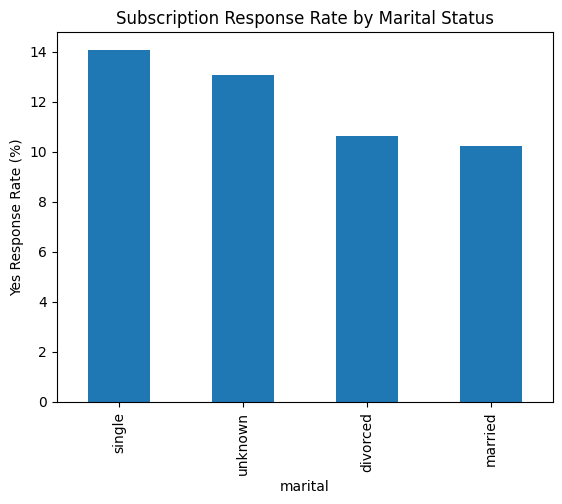

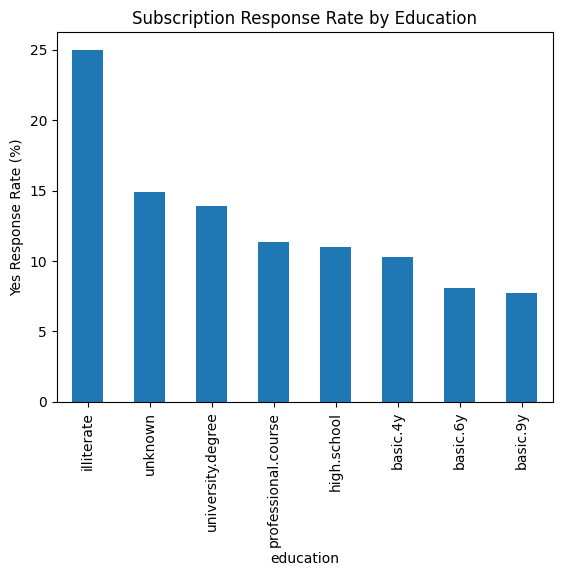

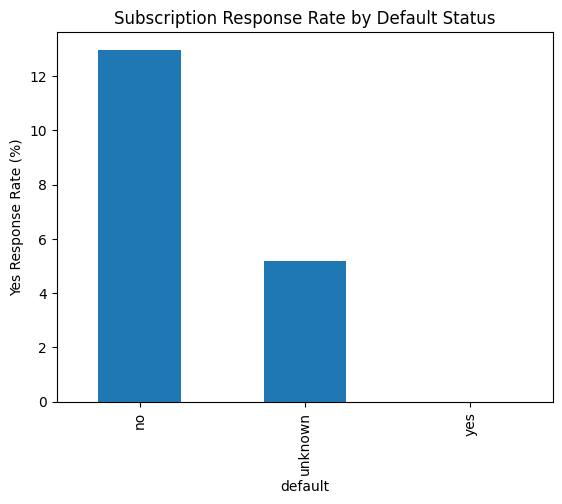

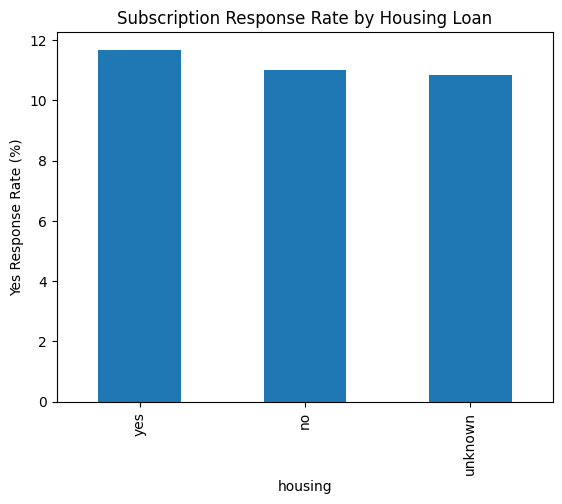

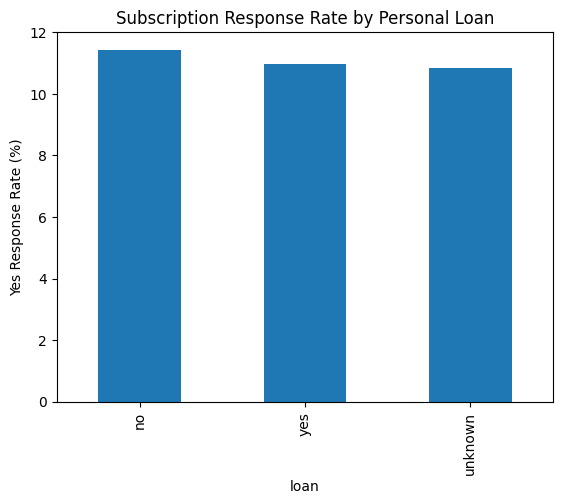

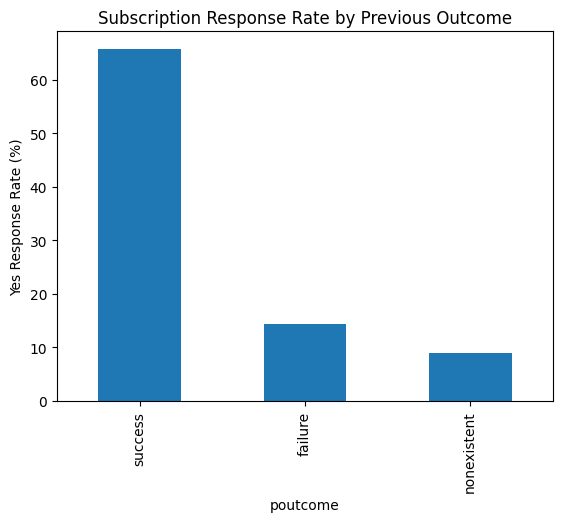

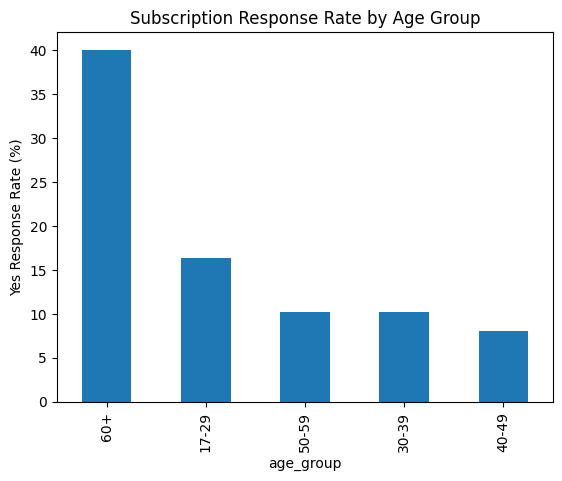

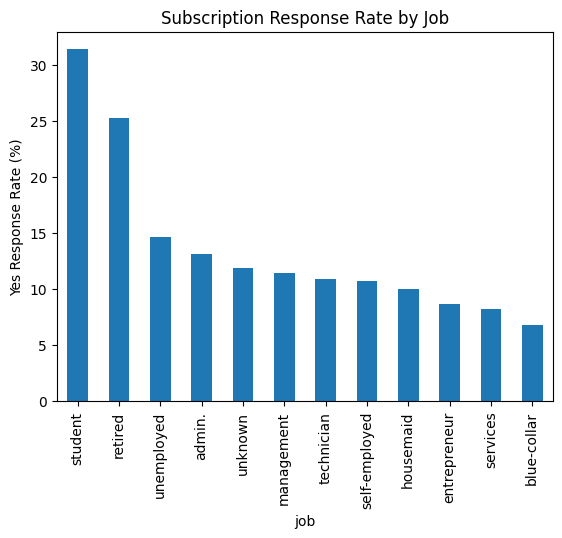

In [4]:
#Visuals to understand WHO responds to the marketing

#Marriage
marital_response = bank_data.groupby("marital")["y"].value_counts().unstack(fill_value=0)
marital_response["yes_percent"] = marital_response["yes"] / (marital_response["yes"] + marital_response["no"]) * 100
marital_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Marital Status")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Education
education_response = bank_data.groupby("education")["y"].value_counts().unstack(fill_value=0)
education_response["yes_percent"] = education_response["yes"] / (education_response["yes"] + education_response["no"]) * 100
education_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Education")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Default status
default_response = bank_data.groupby("default")["y"].value_counts().unstack(fill_value=0)
default_response["yes_percent"] = default_response["yes"] / (default_response["yes"] + default_response["no"]) * 100
default_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Default Status")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Housing loan
housing_response = bank_data.groupby("housing")["y"].value_counts().unstack(fill_value=0)
housing_response["yes_percent"] = housing_response["yes"] / (housing_response["yes"] + housing_response["no"]) * 100
housing_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Housing Loan")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Personal loan
loan_response = bank_data.groupby("loan")["y"].value_counts().unstack(fill_value=0)
loan_response["yes_percent"] = loan_response["yes"] / (loan_response["yes"] + loan_response["no"]) * 100
loan_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Personal Loan")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Previous campaign outcome
poutcome_response = bank_data.groupby("poutcome")["y"].value_counts().unstack(fill_value=0)
poutcome_response["yes_percent"] = poutcome_response["yes"] / (poutcome_response["yes"] + poutcome_response["no"]) * 100
poutcome_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Previous Outcome")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Age groups
bank_data["age_group"] = pd.cut(
    bank_data["age"],
    bins=[16, 29, 39, 49, 59, 98],
    labels=["17-29", "30-39", "40-49", "50-59", "60+"]
)

#Age
age_response = bank_data.groupby("age_group", observed=True)["y"].value_counts().unstack(fill_value=0)
age_response["yes_percent"] = age_response["yes"] / (age_response["yes"] + age_response["no"]) * 100
age_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Age Group")
plt.ylabel("Yes Response Rate (%)")
plt.show()


#Job
job_response = bank_data.groupby("job")["y"].value_counts().unstack(fill_value=0)
job_response["yes_percent"] = job_response["yes"] / (job_response["yes"] + job_response["no"]) * 100
job_response["yes_percent"].sort_values(ascending=False).plot(kind="bar", title="Subscription Response Rate by Job")
plt.ylabel("Yes Response Rate (%)")
plt.show()

### Section 2 (model that predicts who will subscribe)

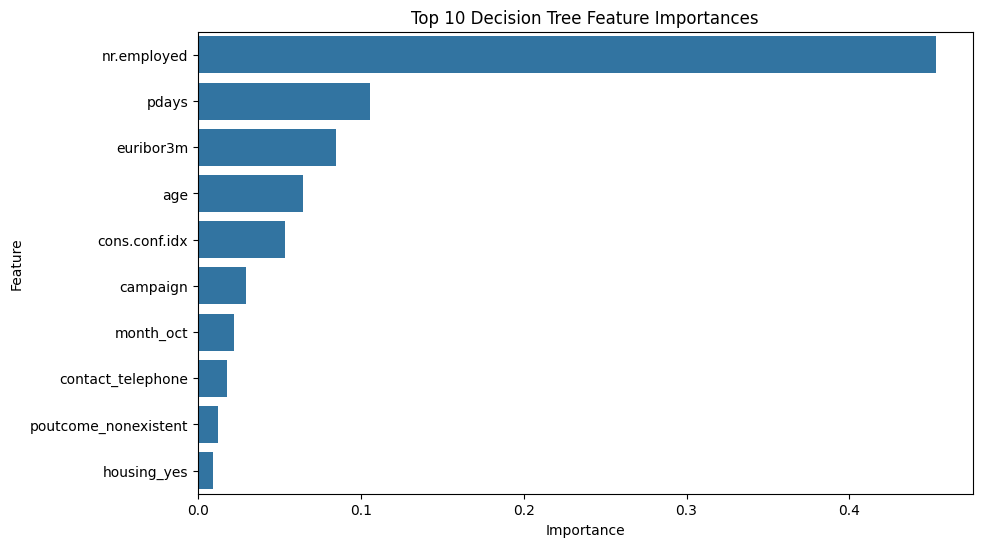

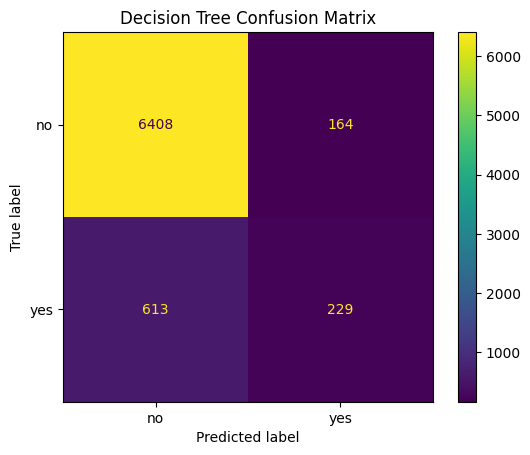

In [5]:
# Check the target distribution
bank_data["y"].value_counts()

# Prepare data
X = bank_data.drop("y", axis=1)
y = bank_data["y"]

# Convert categorical features into numerical features
# We need to do this as scikit-learn need numerical inputs, it can not
# understand values like "admin", "married"...
X = pd.get_dummies(X, drop_first=True)

# Split data (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y # as the data is inbalanced we use stratify to keep the same ratio
)

# Create decision tree
clf = DecisionTreeClassifier(
    random_state=42
)

# Train it
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

# Tune and evaluate different depths (data is inbalanced so accuracy will be bias)
depths = [3, 5, 7, 10, 15, 20]
results = []

for depth in depths:
    clf = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    report = classification_report(
        y_test,
        y_pred,
        output_dict=True
    )

    results.append({
        "max_depth": depth,
        "accuracy": report["accuracy"],
        "yes_precision": report["yes"]["precision"],
        "yes_recall": report["yes"]["recall"],
        "yes_f1": report["yes"]["f1-score"]
    })
results_df = pd.DataFrame(results)
results_df

# Final model and evalute

final_tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

final_tree.fit(X_train, y_train)

# Feature importance
importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": final_tree.feature_importances_
}).sort_values("importance", ascending=False)

importance.head(10)

# Visualization feature importance

top_features = importance.head(10)
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"

)

plt.title("Top 10 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

# Visualization confusion matrix

y_pred_final = final_tree.predict(X_test)
cm = confusion_matrix(y_test, y_pred_final)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=final_tree.classes_
)

disp.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Save model
with open("decision_tree_model.pkl", "wb") as file:
    pickle.dump(final_tree, file, protocol=5)


### Section 3 Random Forest

In [6]:
# Importing necessary libraries

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import pickle
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

In [7]:
# importing the Data

bank_data = pd.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bank.csv')


In [8]:
# Getting the data ready, Splitting it into X and Y

X = bank_data.drop("y", axis=1)
y = bank_data["y"]
X = pd.get_dummies(X, drop_first=True)

In [9]:
# Train, Test Split Set up 80/20

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y
)

In [10]:
# Setting up Random Forest Classifier, Fitting the Model and Making Predictions

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

In [11]:
# Model Score

rf.score(X_test, y_test) # Checking the Model Score

0.8919611545724305

In [12]:
# Classification Report

print (classification_report (y_test, y_pred))

              precision    recall  f1-score   support

          no       0.92      0.97      0.94      6572
         yes       0.54      0.30      0.39       842

    accuracy                           0.89      7414
   macro avg       0.73      0.63      0.66      7414
weighted avg       0.87      0.89      0.88      7414



In [13]:
# Classification Report in greater detail


print ("Accuracy:", rf.score(X_test, y_test))
print ("Precision:", classification_report(y_test, y_pred))
print ("Recall:", classification_report(y_test, y_pred))
print ("F1 Score:", classification_report(y_test, y_pred))

Accuracy: 0.8919611545724305
Precision:               precision    recall  f1-score   support

          no       0.92      0.97      0.94      6572
         yes       0.54      0.30      0.39       842

    accuracy                           0.89      7414
   macro avg       0.73      0.63      0.66      7414
weighted avg       0.87      0.89      0.88      7414

Recall:               precision    recall  f1-score   support

          no       0.92      0.97      0.94      6572
         yes       0.54      0.30      0.39       842

    accuracy                           0.89      7414
   macro avg       0.73      0.63      0.66      7414
weighted avg       0.87      0.89      0.88      7414

F1 Score:               precision    recall  f1-score   support

          no       0.92      0.97      0.94      6572
         yes       0.54      0.30      0.39       842

    accuracy                           0.89      7414
   macro avg       0.73      0.63      0.66      7414
weighted avg    

In [14]:
# Feature Importances Analysis

features = pd.DataFrame(rf.feature_importances_, index=X.columns)
features.head()


,0
age,0.172862
campaign,0.084720
pdays,0.039191
previous,0.016353
emp.var.rate,0.026835


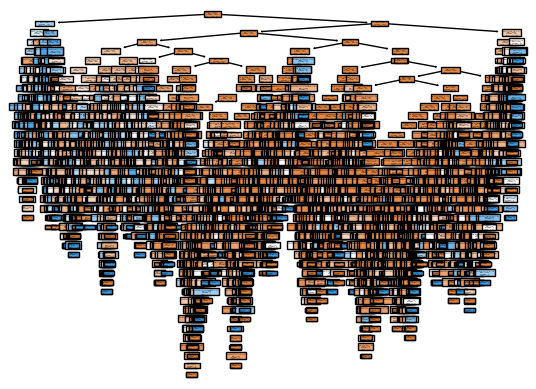

In [22]:
plot_tree(rf.estimators_[0], feature_names=X.columns, filled=True)
plt.show()

In [15]:
# Adding Hyperparameters and Fitting Model

rf2 = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5, min_samples_split=10, min_samples_leaf=5)
rf2.fit(X_train, y_train)

RandomForestClassifier(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [16]:
# Checking Score Difference
rf2.score(X_test, y_test)  #Barley went up ( prevesously 0.8919611545724305)

0.8974912328028055

In [17]:
# Final Classification Report

y_pred = rf2.predict(X_test)
print (classification_report (y_test, y_pred))


              precision    recall  f1-score   support

          no       0.90      0.99      0.94      6572
         yes       0.68      0.18      0.29       842

    accuracy                           0.90      7414
   macro avg       0.79      0.59      0.62      7414
weighted avg       0.88      0.90      0.87      7414



### Section 4

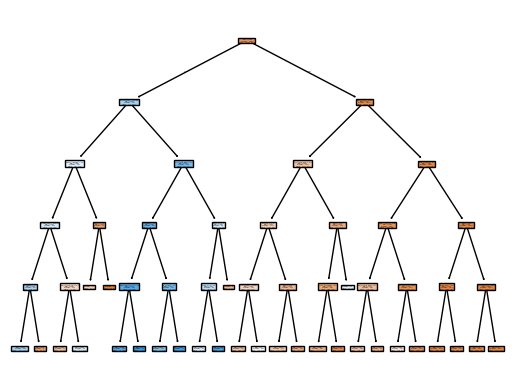

In [20]:
plot_tree(rf2.estimators_[0], feature_names=X.columns, filled=True)
plt.show()


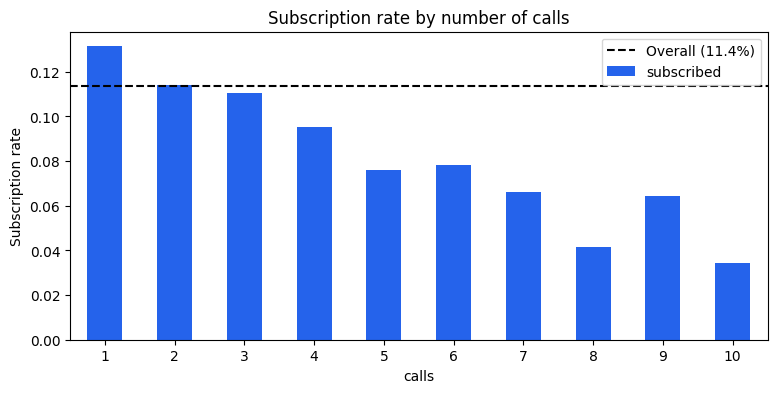

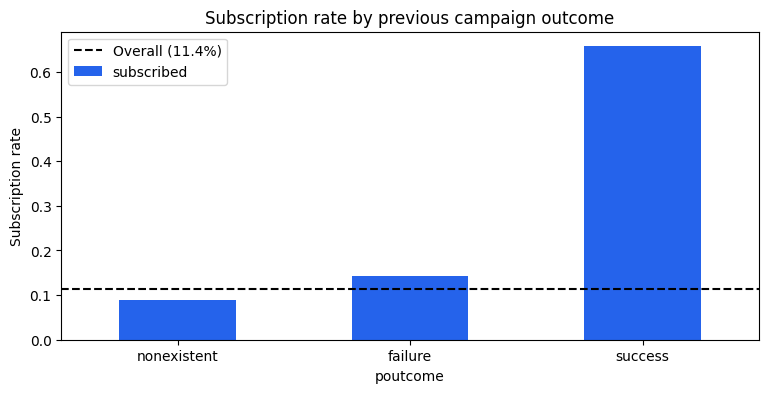

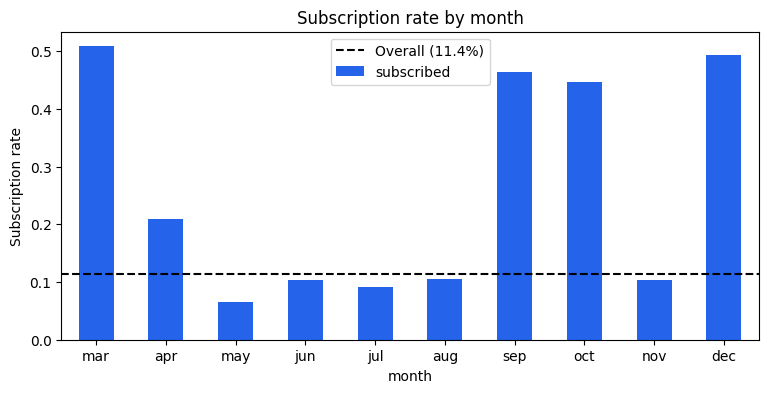

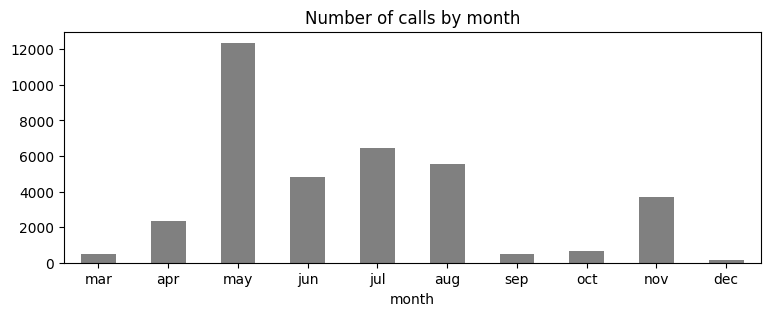

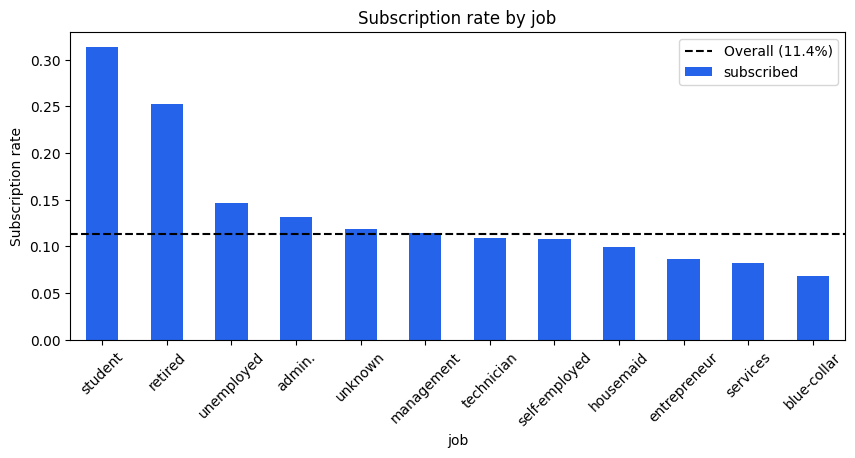

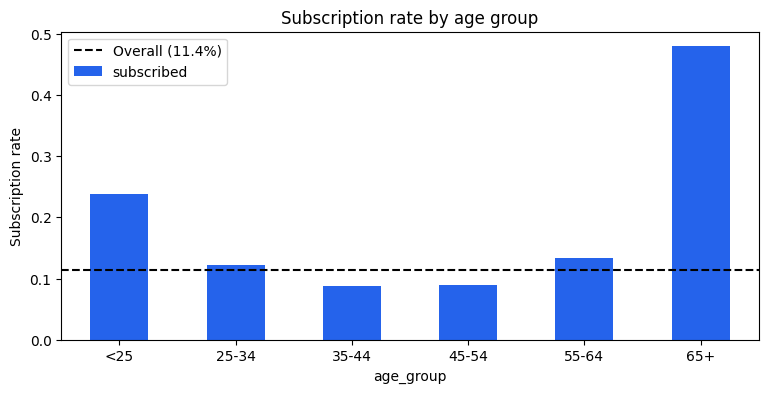

,subscribed
age_group,
<25,0.238241
25-34,0.122389
35-44,0.086953
45-54,0.088812
55-64,0.134124
65+,0.479132


In [19]:
df = bank_data.copy()

df['subscribed'] = (df['y'] == 'yes').astype(int)
overall = df['subscribed'].mean()

def plot_rate(column, title, order=None):
    rates = df.groupby(column, observed=True)['subscribed'].mean()
    if order is not None:
        rates = rates.reindex([x for x in order if x in rates.index])
    ax = rates.plot(kind='bar', color='#2563eb', figsize=(9, 4), rot=0)
    ax.axhline(overall, color='black', linestyle='--', label=f'Overall ({overall:.1%})')
    ax.set_title(title)
    ax.set_ylabel('Subscription rate')
    ax.legend()
    plt.show()
    return rates


df['calls'] = df['campaign'].clip(upper=10)
plot_rate('calls', 'Subscription rate by number of calls')

plot_rate('poutcome', 'Subscription rate by previous campaign outcome',
          order=['nonexistent', 'failure', 'success'])

months = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
plot_rate('month', 'Subscription rate by month', order=months)
df['month'].value_counts().reindex(months).dropna().plot(kind='bar', color='gray', figsize=(9, 3), rot=0,
                                                         title='Number of calls by month')
plt.show()

rates = df.groupby('job')['subscribed'].mean().sort_values(ascending=False)
ax = rates.plot(kind='bar', color='#2563eb', figsize=(10, 4), rot=45)
ax.axhline(overall, color='black', linestyle='--', label=f'Overall ({overall:.1%})')
ax.set_title('Subscription rate by job'); ax.set_ylabel('Subscription rate'); ax.legend()
plt.show()


df['age_group'] = pd.cut(df['age'], bins=[0, 24, 34, 44, 54, 64, 120],
labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])
plot_rate('age_group', 'Subscription rate by age group')